# Retailer Sales Analysis

## Dataset Overview

- **File:** Retail_Sales_Performance_Analysis_Final.xlsx (retailer sales data)
- **Size:** 500 orders and 26 columns
- **Period covered:** 1 May 2026 to 30 Jun 2026
- **Objective:** clean the retailer sales data, calculate core business KPIs, identify sales trends and customer patterns, and present findings with charts and recommendations.

In [ ]:
import pandas as pd
df = pd.read_excel('/content/drive/MyDrive/Retail_Sales_Performance_Analysis_Final.xlsx')

In [ ]:
pd.set_option("display.max_columns", None) #to show all 26 cols
df.head()

,Order ID,Invoice ID,Order Date,Month,City,Customer ID,Customer Name,Gender,Customer Type,Product Category,Product Name,Brand,Quantity,Unit Price,Discount %,Sales,Cost,Profit,Payment Mode,Customer Rating,Delivery Status,Sales Executive,Profit Margin%,Customer Segment,order Size,Day
0,ORD1001,INV5001,46162,May,Faridabad,CUST2042,Aditi Gupta,Female,Retail,Window Cooler,Ozone,Crompton,2,11747,15,19969.9,16132.93,3836.97,UPI,3,In Transit,Priya,0.192138,Medium Value,Regular Order,Wednesday
1,ORD1002,INV5002,46184,June,Muradabad,CUST2135,Dev Sharma,Male,Retail,Personal Cooler,PX97 Torque,Bajaj,1,7402,10,6661.8,5321.62,1340.18,Cash,4,Delivered,Neha,0.201174,Low Value,Regular Order,Thursday
2,ORD1003,INV5003,46158,May,Ghaziabad,CUST2115,Yash Gupta,Male,Dealer,Desert Cooler,Symphony Diet 35T,Symphony,4,16407,0,65628.0,51271.85,14356.15,Bank Transfer,4,In Transit,Rahul,0.218750,High Value,Bulk Order,Saturday
3,ORD1004,INV5004,46156,May,Meerut,CUST2177,Mehak Sharma,Female,Retail,Personal Cooler,Fresco,Orient,1,7676,5,7292.2,5947.31,1344.89,UPI,5,Delivered,Neha,0.184429,Low Value,Regular Order,Thursday
4,ORD1005,INV5005,46163,May,Meerut,CUST2173,Saurabh Sharma,Male,Retail,Desert Cooler,Symphony Diet 35T,Symphony,2,15670,10,28206.0,22427.66,5778.34,Cash,5,In Transit,Mohit,0.204862,Medium Value,Regular Order,Thursday


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          500 non-null    object 
 1   Invoice ID        500 non-null    object 
 2   Order Date        500 non-null    int64  
 3   Month             500 non-null    object 
 4   City              500 non-null    object 
 5   Customer ID       500 non-null    object 
 6   Customer Name     500 non-null    object 
 7   Gender            500 non-null    object 
 8   Customer Type     500 non-null    object 
 9   Product Category  500 non-null    object 
 10  Product Name      500 non-null    object 
 11  Brand             500 non-null    object 
 12  Quantity          500 non-null    int64  
 13  Unit Price        500 non-null    int64  
 14  Discount %        500 non-null    int64  
 15  Sales             500 non-null    float64
 16  Cost              500 non-null    float64
 1

In [ ]:
df.describe()

,Order Date,Quantity,Unit Price,Discount %,Sales,Cost,Profit,Customer Rating,Profit Margin%
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,46171.880000,2.144000,12320.470000,5.820000,24965.168700,19934.355400,5030.813300,4.434000,0.206330
std,18.660494,1.286302,4368.512319,4.875977,18255.847994,14640.150287,3638.970252,0.671227,0.029447
min,46143.000000,1.000000,803.000000,0.000000,1063.000000,692.340000,370.660000,3.000000,0.180006
25%,46155.000000,1.000000,8619.250000,0.000000,13910.137500,11028.805000,2703.215000,4.000000,0.190785
50%,46171.000000,2.000000,12563.500000,5.000000,17080.300000,13700.710000,3495.115000,5.000000,0.202060
75%,46188.250000,3.000000,16317.750000,10.000000,32166.200000,25402.790000,6429.602500,5.000000,0.211702
max,46203.000000,5.000000,17998.000000,15.000000,84390.000000,68431.460000,18276.200000,5.000000,0.405389


In [ ]:
# missing values
print(df.isnull().sum())

# duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Repeated Order IDs:", df["Order ID"].duplicated().sum())

# validation
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Zero or negative sales:", (df["Sales"] <= 0).sum())
print(df["Delivery Status"].unique())
print(df["Product Category"].unique())
print(df["Order Date"].min(), df["Order Date"].max())

Order ID            0
Invoice ID          0
Order Date          0
Month               0
City                0
Customer ID         0
Customer Name       0
Gender              0
Customer Type       0
Product Category    0
Product Name        0
Brand               0
Quantity            0
Unit Price          0
Discount %          0
Sales               0
Cost                0
Profit              0
Payment Mode        0
Customer Rating     0
Delivery Status     0
Sales Executive     0
Profit Margin%      0
Customer Segment    0
order Size          0
Day                 0
dtype: int64
Duplicate rows: 0
Repeated Order IDs: 0
Negative quantity: 0
Zero or negative sales: 0
['In Transit' 'Delivered' 'Cancelled']
['Window Cooler' 'Personal Cooler' 'Desert Cooler' 'Fan Motor'
 'Voltage Stabilizer' 'Tower Cooler' 'Cooling Pad']
46143 46203


In [ ]:
# only problem is date col have datatype int, insted of datetime.
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    unit='D',
    origin='1899-12-30'
)
df['Order Date'].head()

,Order Date
0,2026-05-20
1,2026-06-11
2,2026-05-16
3,2026-05-14
4,2026-05-21


In [ ]:
#save the cleaned file
df.to_csv("cleaned_retail_sales.csv", index=False)

## Data Cleaning Summary

The raw Excel file was left unchanged. All cleaning was done on a copy in this notebook, and the cleaned data was saved separately as `cleaned_retail_sales.csv`.

| Check | What I did | Result |
|---|---|---|
| Missing values | Counted nulls in every column | No missing values found |
| Duplicate rows | Checked for fully duplicated rows | None found |
| Repeated Order IDs | Checked if any Order ID appears more than once | None found |
| Negative quantity | Checked for quantity below 0 | None found |
| Zero or negative sales | Checked for sales of 0 or below | None found |
| Delivery Status and Product Category | Listed the unique values to look for spelling variations | Values were consistent |
| Order Date | Checked the date column and its range | Dates were stored as Excel serial numbers, so they were converted to real dates |

**Date fix:** The Order Date column came from Excel as serial numbers instead of real dates. I converted them with `pd.to_datetime()` so they show as proper dates (1 May 2026 to 30 Jun 2026). This was necessary for the weekly trend analysis because the data is from 1 May 2026 to 30 Jun 2026(2 months).

**Decision:** The date format was the only problem. The data had no missing values, duplicates or invalid entries, so no rows were deleted or filled in.

#**Finding KPI from here**

In [ ]:
total_revenue = df["Sales"].sum()
total_orders  = df["Order ID"].nunique()
avg_order_val = total_revenue / total_orders
total_units   = df["Quantity"].sum()
top_category  = df.groupby("Product Category")["Sales"].sum().idxmax()
top_product   = df.groupby("Product Name")["Sales"].sum().idxmax()

print(total_revenue, total_orders, avg_order_val, total_units, top_category, top_product,sep="\n")

12482584.35
500
24965.1687
1072
Desert Cooler
Symphony Diet 35T


In [ ]:
print(df.groupby("Delivery Status")["Sales"].agg(["sum", "count"]))

                         sum  count
Delivery Status                    
Cancelled          446312.85     19
Delivered        11059071.65    443
In Transit         977199.85     38


In [ ]:
print(df.groupby("Product Category")["Sales"].sum().sort_values(ascending=False))
print(df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(5))
print(df["Payment Mode"].value_counts())
print(df["Customer Segment"].value_counts())
print(df.groupby(df["Order Date"].dt.to_period("W"))["Sales"].sum())
df.groupby("Product Category")["Customer Rating"].agg(["mean", "count"])

Product Category
Desert Cooler         7874142.80
Personal Cooler       2346717.30
Tower Cooler          1400463.90
Window Cooler          737404.10
Voltage Stabilizer      98515.40
Fan Motor               15659.55
Cooling Pad              9681.30
Name: Sales, dtype: float64
City
Ghaziabad        3513527.20
Noida            2267410.20
Greater Noida    1965270.25
Meerut           1573718.55
Muradabad        1289030.70
Name: Sales, dtype: float64
Payment Mode
UPI              233
Cash             145
Card             100
Bank Transfer     22
Name: count, dtype: int64
Customer Segment
Medium Value    174
Low Value       171
High Value      155
Name: count, dtype: int64
Order Date
2026-04-27/2026-05-03     835178.85
2026-05-04/2026-05-10    1444146.70
2026-05-11/2026-05-17    1439888.95
2026-05-18/2026-05-24    1630016.55
2026-05-25/2026-05-31    1240942.20
2026-06-01/2026-06-07    1449083.20
2026-06-08/2026-06-14    1471853.05
2026-06-15/2026-06-21     901978.10
2026-06-22/2026-06-28    1

,mean,count
Product Category,,
Cooling Pad,4.200000,5
Desert Cooler,4.449580,238
Fan Motor,5.000000,6
Personal Cooler,4.394366,142
Tower Cooler,4.450000,60
Voltage Stabilizer,4.625000,16
Window Cooler,4.303030,33


In [ ]:
# share of revenue by category (col / total * 100)
cat = df.groupby("Product Category")["Sales"].sum()
print((cat / cat.sum() * 100).round(1))

# share of revenue by city
city = df.groupby("City")["Sales"].sum()
print((city / city.sum() * 100).round(1).sort_values(ascending=False).head(5))

# share of orders by payment mode and delivery status
print((df["Payment Mode"].value_counts(normalize=True) * 100).round(1))
print((df["Delivery Status"].value_counts(normalize=True) * 100).round(1))

Product Category
Cooling Pad            0.1
Desert Cooler         63.1
Fan Motor              0.1
Personal Cooler       18.8
Tower Cooler          11.2
Voltage Stabilizer     0.8
Window Cooler          5.9
Name: Sales, dtype: float64
City
Ghaziabad        28.1
Noida            18.2
Greater Noida    15.7
Meerut           12.6
Muradabad        10.3
Name: Sales, dtype: float64
Payment Mode
UPI              46.6
Cash             29.0
Card             20.0
Bank Transfer     4.4
Name: proportion, dtype: float64
Delivery Status
Delivered     88.6
In Transit     7.6
Cancelled      3.8
Name: proportion, dtype: float64


## KPI Summary

All 500 orders are included in the KPIs. 19 orders (about 3.8% of orders, 4.46 lakh in sales) were cancelled and 38 are still in transit, so revenue may be slightly overstated.

| KPI | Value | Meaning |
|---|---|---|
| Total Revenue | 12,482,584.35 (about 1.25 crore) | Total sales value of all orders, after discounts |
| Total Orders | 500 | Number of unique orders |
| Average Order Value | 24,965.17 | Total revenue divided by total orders |
| Total Units Sold | 1,072 | Sum of quantities sold |
| Top Category | Desert Cooler | Category with the highest revenue |
| Top Product | Symphony Diet 35T | Product with the highest revenue |

## Key Findings

1. **Category:** Desert Cooler brings in about 63% of revenue, and the top three categories (Desert, Personal and Tower coolers) together give about 93%. Fan Motor, Cooling Pad and Voltage Stabilizer make up only about 1%.
2. **City:** Ghaziabad is the top city with about 28% of revenue, and the top five cities together contribute about 85%.
3. **Payment mode:** UPI is the most used (about 47% of orders), then cash (29%) and card (20%). Bank transfer is rare (about 4%).
4. **Delivery status:** About 89% of orders were delivered, 7.6% are in transit, and 3.8% were cancelled.
5. **Weekly trend:** Weekly sales were steady at about 14-16 lakh, peaking in the week of 18-24 May (about 16.3 lakh). The week of 15-21 June dipped to about 9.0 lakh, about 38% below the usual level. The data doesn't explain why. (The first and last weeks are partial, so they're not counted.)
6. **Customers:** Orders are spread almost evenly across the Medium (174), Low (171) and High Value (155) segments, so no single segment dominates the order count.

# Visualization

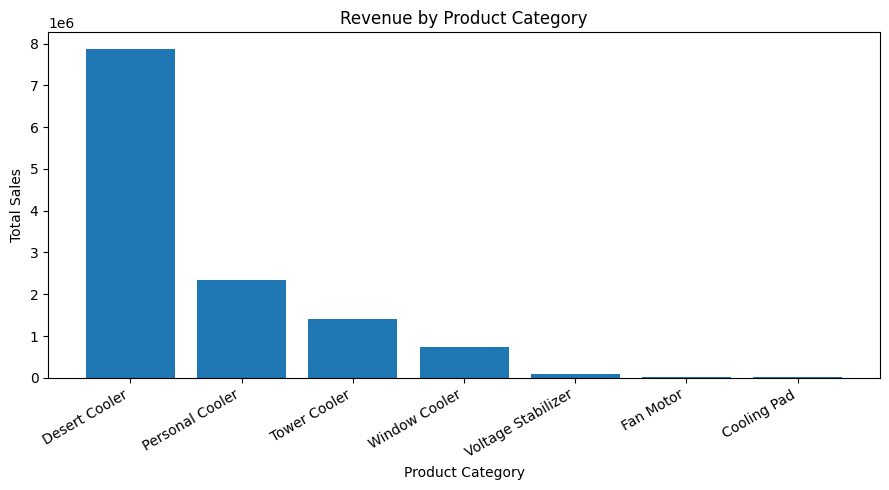

In [ ]:
import matplotlib.pyplot as plt

cat = df.groupby("Product Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(cat.index, cat.values)
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Desert Cooler earns far more than any other category, about 63% of total revenue (around 78.7 lakh). Personal Cooler and Tower Cooler come next with 18.8% and 11.2% of revenue, and Window Cooler is a distant fourth. Voltage Stabilizer, Fan Motor and Cooling Pad earn so little that their bars are barely visible. This shows the business depends mostly on Desert Coolers.

# Trend analysis

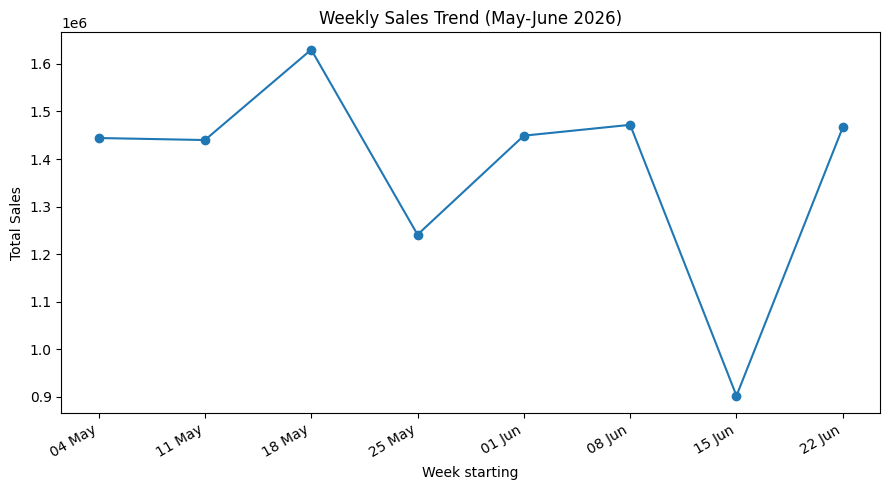

In [ ]:
weekly = df.groupby(df["Order Date"].dt.to_period("W"))["Sales"].sum()
weekly = weekly.iloc[1:-1]   # drop the first and last weeks, because they are partial
labels = weekly.index.start_time.strftime("%d %b")

plt.figure(figsize=(9, 5))
plt.plot(labels, weekly.values, marker="o")
plt.title("Weekly Sales Trend (May-June 2026)")
plt.xlabel("Week starting")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Weekly sales were mostly steady at around 14-15 lakh, peaking in the week starting 18 May at about 16.3 lakh. There were two dips: a small one in the week starting 25 May (about 12.4 lakh) and a sharp one in the week starting 15 June (about 9.0 lakh, roughly 38% below the usual level). Sales recovered the following week. The data doesn't show what caused the dips. The first and last weeks were left out because they only cover part of a week.



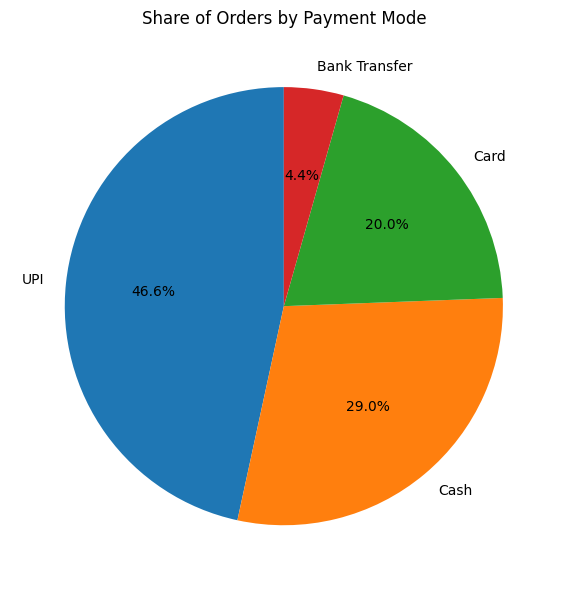

In [ ]:
pay = df["Payment Mode"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(pay.values, labels=pay.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Orders by Payment Mode")
plt.tight_layout()
plt.show()

UPI is the most used payment mode, covering about 47% of orders, followed by cash (29%) and card (20%). Bank transfer is rare at about 4%. Digital payments (UPI and card) make up roughly two-thirds of orders, while cash payments still make up a significant share of customer transactions.

## Customer Insights

**Customer segments:** Orders are spread almost evenly across the Medium (174), Low (171) and High Value (155) segments, so no single segment dominates the order count. The business does not depend on one type of customer.

**Payment behavior:** UPI is the most preferred payment mode, used in about 47% of orders, followed by cash (29%) and card (20%). Bank transfer is rare at about 4%. UPI and card together cover roughly two-thirds of orders, so most customers prefer digital payments. Cash still accounts for almost 3 in 10 orders, which means a large share of customers like to pay on delivery or in person.

**Customer base:** The 500 orders came from 167 unique customers, about 3 orders per customer. This means customers buy repeatedly: at least 333 orders (about 67%) were repeat purchases, made after a customer's first order. Since repeat buying is so common, keeping existing customers happy matters as much as finding new ones.


*  Calculation : 167 orders are first orders (one per customer), so 500 − 167 = 333 are repeat orders, and 333 ÷ 500 = 67%.



## Recommendations

1. **Protect and grow the Desert Cooler line.** Desert Coolers bring in about 63% of revenue, so keeping them well stocked before and during the season matters most.
2. **Review the low-earning categories.** Fan Motor, Cooling Pad and Voltage Stabilizer together make up only about 1% of revenue. The business could test bundling them with coolers as add-ons, or reduce the stock it holds for them.
3. **Reduce dependence on a few cities.** Ghaziabad gives about 28% of revenue and the top five cities about 85%. Marketing in the other cities could be tested to spread the risk.
4. **Look into the cancelled and in-transit orders.** About 3.8% of orders were cancelled and 7.6% are still in transit. Finding out why would help protect revenue.
5. **Investigate the June dip.** Sales in the week of 15 June fell about 38% below the usual level. Checking stock, delivery or local events for that week could show whether it can be avoided next time.

## Limitations and Assumptions

- **Cancelled and in-transit orders are included.** All 500 orders are counted in revenue, including 19 cancelled and 38 in-transit orders, so revenue may be slightly overstated.
- **Short time period.** The data covers only two months (May to June 2026), so I can't say anything about seasonal patterns across a full year.
- **Partial weeks removed.** The first and last weeks of the data are partial, so they were left out of the weekly trend.
- **Causes are not known.** The data shows what happened, for example the June dip, but not why. The recommendations are suggestions to investigate, not proven causes.
- **Customer analysis basis.** Customer insights are drawn from customer segments, payment mode and order counts per customer. Across 167 customers and 500 orders, about 67% of orders were repeat purchases, showing a strong base of returning customers.